# Extended Data Figure 8

Panels a and e–g are drawn from the worksheets `ED_Fig8a`, `ED_Fig8e`–`ED_Fig8g` of `Wilhelm_SourceData.xlsx`; panels h, i from the per-allele correlations in `Wilhelm_SourceData_ED_Fig8h_i.parquet` (box statistics in `Wilhelm_SourceData_ED_Fig8h_i_summary.csv`). Panels b–d are sequence logos; their information content (bits per position and amino acid) is shown as tables.

Data are loaded with `source_data.py` (same folder) from the figshare deposit: set `FIGSHARE_ARTICLE_ID` in the next cell (or the environment variable of the same name), or `SOURCE_DATA_DIR` to a local copy of the files; while the article is private, set `FIGSHARE_TOKEN`. Panels are saved to `regenerated_panels/ED_Fig8/`.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data'); DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig8'; FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


readme('ED_Fig8')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 8,a,ED_Fig8a,NaN,PSMs gained with Prosit-22PTM rescoring compar...,ED_Fig8a; ED_Fig8a_totals
1,Extended Data Fig. 8,b,ED_Fig8b,NaN,Sequence logo of A*01:01 unmodified peptides: ...,ED_Fig8b
2,Extended Data Fig. 8,c,ED_Fig8c,NaN,Sequence logo of A*01:01 N-deamidated peptides...,ED_Fig8c
3,Extended Data Fig. 8,d,ED_Fig8d,NaN,Sequence logo of A*01:01 S-phosphorylated pept...,ED_Fig8d
4,Extended Data Fig. 8,e,ED_Fig8e,NaN,UMAP coordinates of the latent-space embedding...,ED_Fig8e
5,Extended Data Fig. 8,f,ED_Fig8f,NaN,A*01:01 enriched modified residues: conservati...,ED_Fig8f
6,Extended Data Fig. 8,g,ED_Fig8g,NaN,Clustering frequency (%) of unmodified amino a...,ED_Fig8g
7,Extended Data Fig. 8,h,NaN,Wilhelm_SourceData_ED_Fig8h_i.parquet; Wilhelm...,Pearson and Spearman correlation per HLA allel...,NaN
8,Extended Data Fig. 8,i,NaN,Wilhelm_SourceData_ED_Fig8h_i.parquet,"As h, with shuffled labels; box statistics in ...",NaN


## a — PSMs gained with Prosit-22PTM rescoring vs AlphaPeptDeep + DeepLC

Bars: PSMs gained with Prosit-22PTM rescoring per modification-residue pair (%), coloured by `category`, in the order of `bar (left to right)`. Right: common / gained / lost target PSMs at 1% FDR (table `ED_Fig8a_totals`) as % of the AlphaPeptDeep + DeepLC total (common + lost).

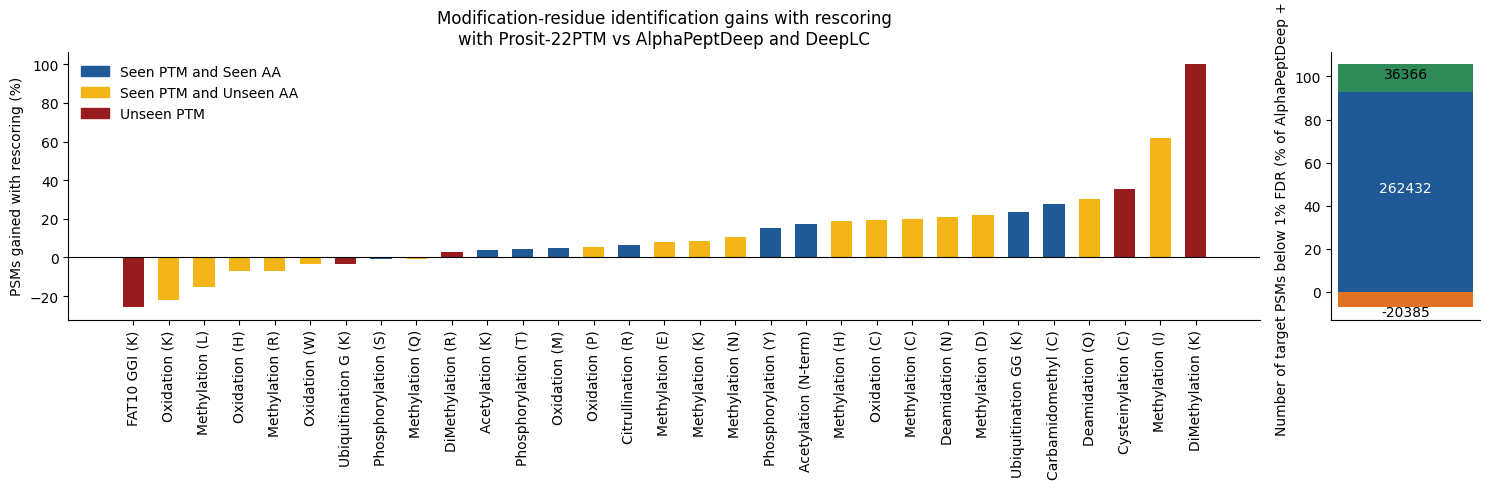

,bar (left to right),modification (residue),category,PSMs_gained_with_rescoring (%)
0,1,FAT10 GGI (K),Unseen PTM,-25.86
1,2,Oxidation (K),Seen PTM and Unseen AA,-22.19
2,3,Methylation (L),Seen PTM and Unseen AA,-15.39
3,4,Oxidation (H),Seen PTM and Unseen AA,-7.17
4,5,Methylation (R),Seen PTM and Unseen AA,-6.86
5,6,Oxidation (W),Seen PTM and Unseen AA,-3.35
6,7,Ubiquitination G (K),Unseen PTM,-3.30
7,8,Phosphorylation (S),Seen PTM and Seen AA,-0.74
8,9,Methylation (Q),Seen PTM and Unseen AA,-0.60
9,10,DiMethylation (R),Unseen PTM,3.01


In [3]:
a = table('ED_Fig8a')
tot = table('ED_Fig8a_totals').set_index('category')['n_target_PSMs (1% FDR)']
COL = {'Seen PTM and Seen AA': '#1f5a96', 'Seen PTM and Unseen AA': '#f2b417', 'Unseen PTM': '#981b1e'}
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [8, 1]})
ax.bar(range(len(a)), a['PSMs_gained_with_rescoring (%)'], color=a['category'].map(COL), width=0.6)
ax.set_xticks(range(len(a)), a['modification (residue)'], rotation=90)
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('PSMs gained with rescoring (%)')
ax.set_title('Modification-residue identification gains with rescoring\nwith Prosit-22PTM vs AlphaPeptDeep and DeepLC')
ax.legend([Patch(color=c) for c in list(COL.values())[:3]], list(COL)[:3], frameon=False, loc='upper left')
common, gained, lost = tot['Common'], tot['Gained'], -tot['Lost']
base = common + lost
ax2.bar(0, 100 * common / base, color='#1f5a96'); ax2.bar(0, 100 * gained / base, bottom=100 * common / base, color='#2e8b57')
ax2.bar(0, -100 * lost / base, color='#e17224')
ax2.text(0, 50 * common / base, f'{common}', ha='center', color='white')
ax2.text(0, 100 * common / base + 50 * gained / base, f'{gained}', ha='center')
ax2.text(0, -100 * lost / base - 4, f'-{lost}', ha='center')
ax2.set_xticks([]); ax2.set_ylabel('Number of target PSMs below 1% FDR (% of AlphaPeptDeep + DeepLC)')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False); ax2.spines[s].set_visible(False)
plt.tight_layout(); save('ED_Fig8a'); plt.show()
a

## b–d — A*01:01 sequence logos

Information content (bits) per position and amino acid: unmodified peptides (b), N-deamidated peptides vs human background (c), S-phosphorylated peptides (d).

In [4]:
display(table('ED_Fig8b').set_index('position (C = C-terminus)').round(2))
display(table('ED_Fig8c').set_index('position (C = C-terminus)').round(2))
display(table('ED_Fig8d').set_index('position (C = C-terminus)').round(2))

,D,E,F,I,L,P,S,T,V,Y
position (C = C-terminus),,,,,,,,,,
1,0.00,0.00,0.16,0.00,0.11,0.00,0.00,0.00,0.00,0.21
2,0.00,0.00,0.00,0.05,0.20,0.00,0.32,0.67,0.07,0.00
3,2.04,0.56,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.07,0.00,0.06,0.00,0.00,0.00,0.00
5,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.00,0.00,0.00
6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,0.00,0.00,0.07,0.00,0.21,0.00,0.00,0.00,0.00,0.00
C-1,0.00,0.00,0.06,0.00,0.22,0.00,0.00,0.00,0.00,0.05
C,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.57


,A,D,E,F,G,H,I,L,N,P,Q,S,T,V,Y
position (C = C-terminus),,,,,,,,,,,,,,,
1,0.10,0.0,0.00,0.18,0.07,0.00,0.00,0.00,0.23,0.06,0.1,0.00,0.00,0.07,0.00
2,0.05,0.0,0.05,0.00,0.11,0.00,0.00,0.17,0.33,0.00,0.0,0.00,0.00,0.00,0.00
3,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,3.73,0.00,0.0,0.00,0.00,0.00,0.00
4,0.00,0.0,0.00,0.07,0.87,0.00,0.00,0.05,0.08,0.00,0.0,0.00,0.11,0.00,0.00
5,0.05,0.1,0.00,0.00,0.34,0.00,0.11,0.00,0.14,0.00,0.0,0.00,0.00,0.38,0.00
6,0.10,0.1,0.00,0.18,0.11,0.09,0.00,0.00,0.00,0.00,0.0,0.05,0.00,0.00,0.00
7,0.31,0.0,0.05,0.00,0.11,0.00,0.00,0.00,0.14,0.00,0.0,0.00,0.00,0.14,0.09
C-1,0.00,0.0,0.00,0.14,0.34,0.00,0.00,0.00,0.14,0.00,0.0,0.00,0.08,0.07,0.27
C,0.00,0.0,0.00,0.00,0.10,0.00,0.17,0.00,0.00,0.00,0.0,0.00,0.00,0.00,3.30


,C,D,F,G,I,L,M,S,T,V,Y
position (C = C-terminus),,,,,,,,,,,
1,0.00,0.00,0.07,0.00,0.07,0.04,0.00,0.10,0.04,0.00,0.00
2,0.00,0.04,0.00,0.06,0.05,0.14,0.00,0.07,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.08,0.00,0.00,0.00
4,0.00,0.00,0.16,0.00,0.00,0.11,0.00,0.12,0.00,0.05,0.00
5,0.00,0.00,0.06,0.08,0.08,0.13,0.00,0.10,0.00,0.00,0.00
6,0.00,0.00,0.00,0.12,0.12,0.10,0.04,0.00,0.00,0.00,0.00
7,0.04,0.08,0.08,0.00,0.06,0.11,0.00,0.06,0.00,0.00,0.00
C-1,0.00,0.00,0.15,0.00,0.00,0.13,0.00,0.16,0.00,0.00,0.00
C,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.99


## e — UMAP of the latent space of amino acids and PTMs (A*01:01)

UMAP coordinates of the latent-space embeddings of amino acids and modified residues, coloured by cluster and labelled with the residue.

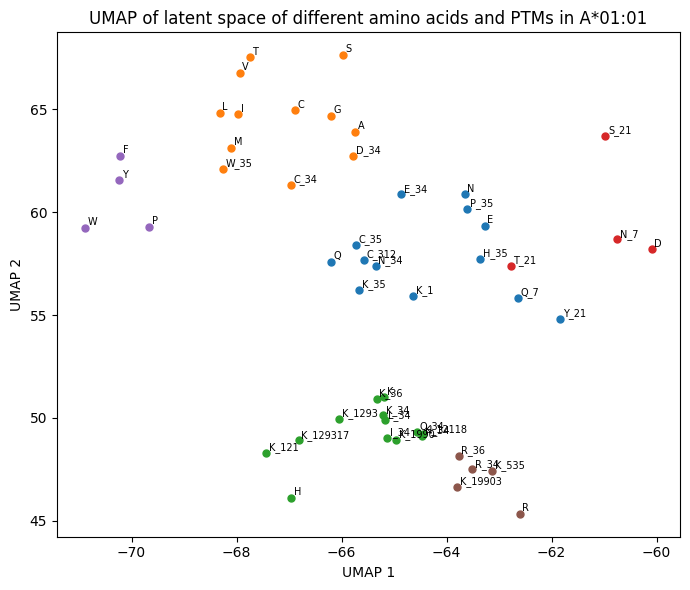

In [5]:
e = table('ED_Fig8e')
fig, ax = plt.subplots(figsize=(7, 6))
for k, g in e.groupby('cluster'):
    ax.scatter(g['UMAP_1'], g['UMAP_2'], s=25, label=f'cluster {k}')
for _, r in e.iterrows():
    ax.annotate(r['residue (AA or AA_UNIMOD)'], (r['UMAP_1'], r['UMAP_2']), fontsize=7, xytext=(2, 2), textcoords='offset points')
ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
ax.set_title('UMAP of latent space of different amino acids and PTMs in A*01:01')
plt.tight_layout(); save('ED_Fig8e'); plt.show()

## f — A*01:01 enriched modified residues

Conservation (bits) vs fraction of UMAP runs in which the modified residue clustered correctly (%); R = Pearson correlation of the plotted values; dashed line = diagonal from (0, 0) to (5.2, 105).

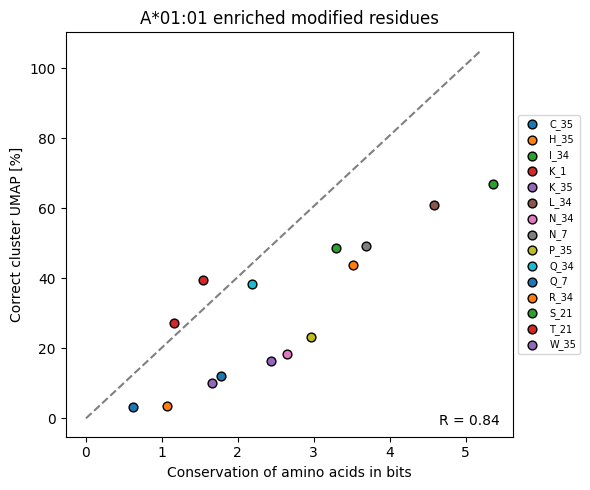

,modified residue (AA_UNIMOD),conservation (bits),correct cluster UMAP (%)
0,C_35,0.625,3.2
1,H_35,1.070,3.6
2,I_34,3.293,48.6
3,K_1,1.155,27.2
4,K_35,1.661,10.2
5,L_34,4.586,61.0
6,N_34,2.642,18.5
7,N_7,3.695,49.3
8,P_35,2.970,23.1
9,Q_34,2.184,38.5


In [6]:
f = table('ED_Fig8f')
fig, ax = plt.subplots(figsize=(6, 5))
for _, r in f.iterrows():
    ax.scatter(r['conservation (bits)'], r['correct cluster UMAP (%)'], s=40, label=r['modified residue (AA_UNIMOD)'], edgecolor='k')
ax.plot([0, 5.2], [0, 105], ls='--', color='grey')
r = np.corrcoef(f['conservation (bits)'], f['correct cluster UMAP (%)'])[0, 1]
ax.text(0.97, 0.03, f'R = {r:.2f}', transform=ax.transAxes, ha='right')
ax.set_xlabel('Conservation of amino acids in bits'); ax.set_ylabel('Correct cluster UMAP [%]')
ax.set_title('A*01:01 enriched modified residues'); ax.legend(fontsize=7, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout(); save('ED_Fig8f'); plt.show()
f

## g — top clustered amino acids with deamidated residues

Clustering frequency (%) of the unmodified amino acids E, D, N and Q with deamidated N and Q.

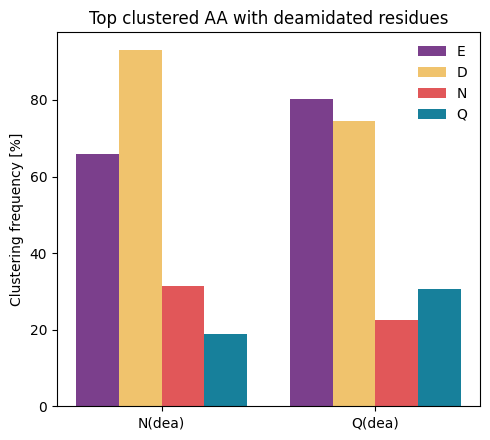

,deamidated residue,unmodified AA,clustering frequency (%)
0,N(dea),E,66.0
1,N(dea),D,93.0
2,N(dea),N,31.3
3,N(dea),Q,19.0
4,Q(dea),E,80.2
5,Q(dea),D,74.5
6,Q(dea),N,22.4
7,Q(dea),Q,30.5


In [7]:
g = table('ED_Fig8g')
CG = {'E': '#7b3f8c', 'D': '#f0c36d', 'N': '#e15759', 'Q': '#17809b'}
fig, ax = plt.subplots(figsize=(5, 4.5))
for i, aa in enumerate(CG):
    s = g[g['unmodified AA'] == aa]
    ax.bar(np.arange(2) + (i - 1.5) * 0.2, s['clustering frequency (%)'], 0.2, color=CG[aa], label=aa)
ax.set_xticks([0, 1], ['N(dea)', 'Q(dea)']); ax.set_ylabel('Clustering frequency [%]')
ax.set_title('Top clustered AA with deamidated residues'); ax.legend(frameon=False)
plt.tight_layout(); save('ED_Fig8g'); plt.show()
g

## h, i — per-allele correlation of UMAP clustering frequency vs modified-residue conservation

Pearson and Spearman correlation per HLA class I allele (n = 94 alleles per panel) between residue conservation and UMAP clustering frequency, with the modified-residue labels (h) and with shuffled labels (i). Box plots: boxes = quartiles, whiskers = 1.5 × IQR, outliers drawn; number = median.

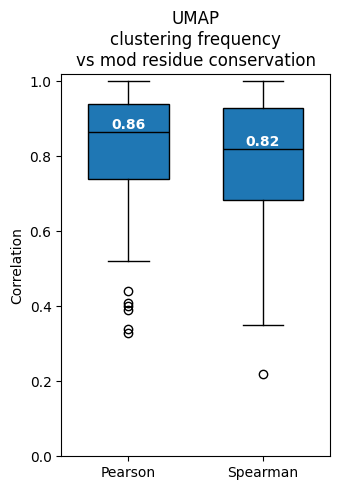

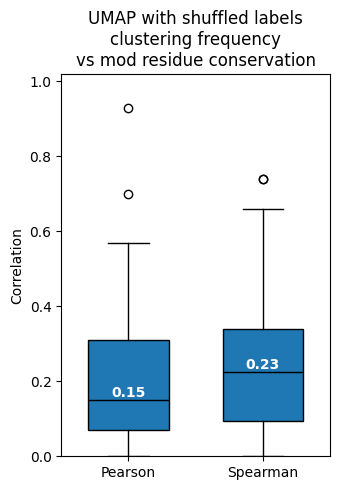

,panel,Pearson correlation count,Pearson correlation median,Pearson correlation Q1,Pearson correlation Q3,Spearman correlation count,Spearman correlation median,Spearman correlation Q1,Spearman correlation Q3
0,ED_Fig8h (UMAP labels),94,0.865,0.74,0.94,94,0.820,0.6825,0.93
1,ED_Fig8i (shuffled labels),94,0.150,0.07,0.31,94,0.225,0.0950,0.34


In [8]:
hi = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig8h_i.parquet'))
for panel, title, name in [('ED_Fig8h (UMAP labels)', 'UMAP\nclustering frequency\nvs mod residue conservation', 'ED_Fig8h'),
                           ('ED_Fig8i (shuffled labels)', 'UMAP with shuffled labels\nclustering frequency\nvs mod residue conservation', 'ED_Fig8i')]:
    d = hi[hi['panel'] == panel]
    vals = [d['Pearson correlation'].values, d['Spearman correlation'].values]
    fig, ax = plt.subplots(figsize=(3.5, 5))
    bp = ax.boxplot(vals, positions=[1, 2], widths=0.6, patch_artist=True, showfliers=True)
    for b in bp['boxes']:
        b.set(facecolor='#1f77b4', edgecolor='black')
    for el in ('whiskers', 'caps', 'medians'):
        plt.setp(bp[el], color='black')
    for p, v in zip([1, 2], vals):
        ax.text(p, np.median(v), f'{np.median(v):.2f}', ha='center', va='bottom', color='white', fontweight='bold')
    ax.set_xticks([1, 2], ['Pearson', 'Spearman']); ax.set_ylabel('Correlation'); ax.set_ylim(0, 1.02); ax.set_title(title)
    plt.tight_layout(); save(name); plt.show()
table('ED_Fig8h_i_summary')